<a href="https://colab.research.google.com/github/roeijacob/Airbnb_Amsterdam_Project/blob/main/Q2_airbnb_GefenT_RoeiJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div = dir = rtl>

**-מגישים-**

גפן טרמצ'י - 211345814

רועי יעקב - 206352221

The chosen city: **AMSTERDAM**

<div = dir = rtl>
קישור לדרייב:  

https://drive.google.com/drive/folders/1T5KeJyEuxYt58YBFWujL5S5siRrY0w5X?usp=drive_link

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/airbnb_proj_roei_gefen/listings airbnb proj roei gefen.csv'
df = pd.read_csv(file_path)

Mounted at /content/drive


#**Part 1 - Data Loading and Initial Exploration**

In [ ]:
print("Five of the first lines in the excel file: ")
display(df.head())
print("Five of the last lines in the excel file: ")
display(df.tail())
print("\nThe shape of the table:", df.shape) #Prints the shape of the table (rows X columns)
print("\nData Types:\n", df.dtypes) #Prints the data types of each coloumn
print("\nNumeric columns:", df.select_dtypes(include='number').columns.tolist()) #Prints the numeric columns
print("\nCategorical columns:", df.select_dtypes(include='object').columns.tolist()) #Prints the Categorial columns
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce') #Change the type of last_review to
df.rename(columns={"calculated_host_listings_count": "number_of_host_assets",
                   "availability_365": "days_available_in_a_year"}, inplace=True) #Renaming two columns
print("\nStatistic summary: ")
df[['price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'number_of_host_assets',
    'days_available_in_a_year',
    'number_of_reviews_ltm']].describe().round(2) #Introducing statistic summary about the relevant columns

Five of the first lines in the excel file: 


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,27886,"Romantic, stylish B&B houseboat in canal district",97647,Flip,NaN,Centrum-West,52.38761,4.89188,Private room,132.0,3,302,11/06/2025,1.85,1,53,28,0363 974D 4986 7411 88D8
1,28871,Comfortable double room,124245,Edwin,NaN,Centrum-West,52.36775,4.89092,Private room,78.0,2,710,16/06/2025,3.93,2,130,93,0363 607B EA74 0BD8 2F6F
2,29051,Comfortable single / double room,124245,Edwin,NaN,Centrum-Oost,52.36584,4.89111,Private room,70.0,2,822,14/06/2025,4.74,2,121,86,0363 607B EA74 0BD8 2F6F
3,44391,Quiet 2-bedroom Amsterdam city centre apartment,194779,Jan,NaN,Centrum-Oost,52.37168,4.91471,Entire home/apt,NaN,3,42,20/08/2022,0.23,1,0,0,0363 E76E F06A C1DD 172C
4,47061,Charming apartment in old centre,211696,Ivar,NaN,De Baarsjes - Oud-West,52.36786,4.87458,Entire home/apt,120.0,2,203,29/05/2025,1.13,1,66,5,0363 1266 8C04 4133 E6AC


Five of the last lines in the excel file: 


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
10163,1437492870456891135,Stylish large apt/with terrace,699642430,Mirte Renée,NaN,Watergraafsmeer,52.347260,4.922780,Entire home/apt,258.0,3,0,NaN,NaN,1,22,0,036374862C87807756B2
10164,1437585511300942515,Sfeervol huis in Amsterdam,7177465,Willemijn,NaN,Gaasperdam - Driemond,52.300682,4.992821,Entire home/apt,350.0,1,0,NaN,NaN,1,332,0,0363 9759 03A5 A885 1861
10165,1437601466510408215,New design apartment next to Westerpark,58139080,Anna,NaN,Westerpark,52.384420,4.872898,Entire home/apt,263.0,5,0,NaN,NaN,1,350,0,0363650F325D464F5384
10166,1437660079651924451,Chateau Hedwig,576071459,Hedwig,NaN,De Baarsjes - Oud-West,52.367560,4.867950,Entire home/apt,300.0,1,0,NaN,NaN,3,359,0,0363 29DA 9893 0B73 3070
10167,1438602403155395239,Central station private flat d,449825081,Dario,NaN,Centrum-West,52.377890,4.896900,Entire home/apt,149.0,1,0,NaN,NaN,3,71,0,0363 6F6A 6A5A 5BDA B659



The shape of the table: (10168, 18)

Data Types:
 id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group               float64
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                             float64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                            object
dtype: object

Numeric columns: ['id', 'host_id', 'neighbourhood_group', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_

,price,minimum_nights,number_of_reviews,reviews_per_month,number_of_host_assets,days_available_in_a_year,number_of_reviews_ltm
count,6321.00,10168.00,10168.00,9198.00,10168.00,10168.00,10168.00
mean,364.92,4.13,47.57,0.98,1.85,91.04,8.97
std,2288.99,17.27,128.11,2.11,3.34,116.07,25.08
min,8.00,1.00,0.00,0.01,1.00,0.00,0.00
25%,162.00,2.00,3.00,0.20,1.00,0.00,0.00
50%,223.00,3.00,10.00,0.41,1.00,26.00,2.00
75%,315.00,4.00,31.00,0.92,1.00,167.00,6.00
max,80018.00,1001.00,4792.00,99.01,39.00,365.00,848.00


**משתנים מספריים-** id, host_id, neighbourhood_group, latitude, longitude, price, minimum_nights, number_of_reviews, reviews_per_month, calculated_host_listings_count, availability_365, number_of_reviews_ltm

**משתנים טקסטואליים-** name, host_name, neighbourhood, room_type, last_review, license

#**Part 2 - Data Cleaning and Preprocessing**

##**נתונים חסרים**

Number of Missing Values per Column: 

host_name                  4
neighbourhood_group    10168
price                   3847
last_review             6020
reviews_per_month        970
license                  106
dtype: int64


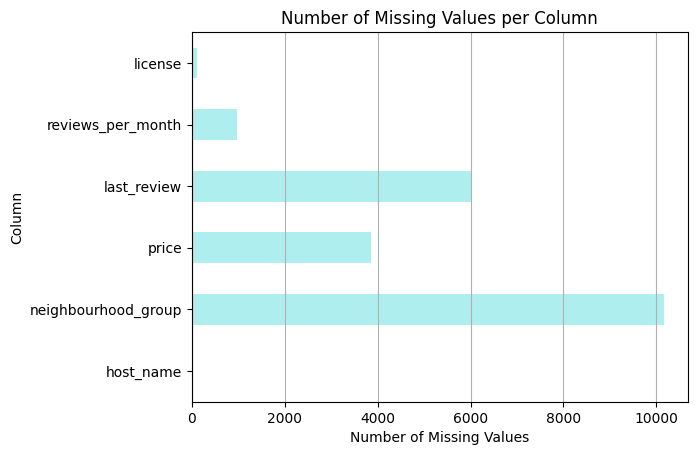

In [ ]:
missing_counts = df.isnull().sum() #For counting missing values in each column
missing_counts = missing_counts[missing_counts > 0] #Filtering the columns with missing values
print("Number of Missing Values per Column: \n")
print(missing_counts)
missing_counts.plot(kind='barh', color='paleturquoise') #Creating a graph that shows the numbers of each column missing values
plt.title('Number of Missing Values per Column')
plt.xlabel('Number of Missing Values')
plt.ylabel('Column')
plt.grid(axis='x')
plt.show()

<div dir="rtl">

**אסטרטגיה לטיפול בערכים חסרים**   

במהלך ניתוח הנתונים מצאנו כי קיימות מספר עמודות בהן ערכים חסרים בטווחים שונים.  
על מנת להתמודד עם החסרים פעלנו במספר גישות:  
1. **מחיקת עמודות-**  
- עמודת license-  
עמודה זו מייצגת את מספר הרישיון של כל נכס. הערכים הקיימים בה אינם שימושיים לניתוח הדאטה, לכן בחרנו להסיר את העמודה.  
- עמודת last_review-  
עמודה זו מייצגת את התאריך האחרון בו השאירו ביקורת על הנכס. מכיוון שמדובר בתאריך ואין באפשרותנו להשלים אותו בצורה מדוייקת ובנוסף נתון זה אינו שימושי לניתוח הדאטה, בחרנו להסיר את העמודה.  
- עמודת neighbourhood_group-  
עמודה זו מייצגת חלוקה של שכונות. בעמודה זו היה חוסר של 10,168 ערכים (מתוך 10,168) כלומר, העמודה כולה הייתה ריקה. מאחר ואין בעמודה זו מידע שימושי ואין ביכולתנו להשלים אותו, בחרנו להסיר אותה.  
2. **השלמת ערכים-**  
- עמודת reviews_per_mount-  
עמודה זו מייצגת את מספר הביקורות שנכתבו על הנכס בחודש. בעמודה זו היה חוסר של 970 ערכים, מכיוון שמדובר בנתון שלא בהכרח רלוונטי לניתוח הדאטה (ייתכן ואנשים פשוט לא השאירו ביקורת), בחרנו להשלים את הערכים החסרים עם הערך 0.  
- עמודת price-  
עמודה זו מייצגת את המחיר ללילה בנכס. בעמודה זו היה חוסר של 3847 ערכים (שזה כמעט שליש מסך הערכים הכולל!), נתון המחיר הוא קריטי לניתוח הדאטה, לכן אי אפשר להשלים את החוסרים עם מספר פשוט (כמו אפס) וגם אי אפשר למחוק את השורות עם הערכים החסרים, דבר שיגרום למחיקת כמעט שליש מהדאטה.  
לכן בחרנו בגישה אחרת- סוגי הנכסים מחולק לשני סוגים עיקריים - חדר פרטי ובית שלם. עבור כל סוג נכס, חושב החציון של מחירו וערך החציון הוכנס לערכים החסרים בהתאמה לסוג הנכס. בחרנו להשתמש בחציון ולא בממוצע מכיוון שממוצע מושפע מערכים קיצוניים (בין אם המחיר נמוך מאוד או גבוה מאוד), החציון מייצג את המחיר מבלי להיות מושפע מקיצון. בגישה זו שמרנו על סטטיסטיקת המחירים ולא מחקנו חלק נכבד מהדאטה שלנו.  
- עמודת host_name-  
עמודה זו מייצגת את שם בעל הנכס, בעמודה זו היה חוסר מינימלי מאוד של 4 ערכים. שם בעל הנכס אינו קריטי לניתוח הדאטה, לכן בחרנו להשלים את החוסרים עם ערך זהה "no name".

In [ ]:
#Creating a copy of the original DF to work on instead of changing the origin:
df_cleaned = df.drop(columns=['neighbourhood_group', 'last_review', 'license']) #Removing empty/unrelevant for data analysis columns
print("Data Frame before changes: \n")
print(df_cleaned.info())
df_cleaned['host_name'] = df_cleaned['host_name'].fillna("no name") #Filling missing values in host_name column
df_cleaned['price'] = df_cleaned.groupby('room_type')['price'].transform(lambda x: x.fillna(x.median())) #Filling missing values in price column with median of each room type
df_cleaned['reviews_per_month'] = df_cleaned['reviews_per_month'].fillna(0) #Filling missing values in reviews_per_month column with 0
print("\nData Frame after changes: \n")
print(df_cleaned.info())

Data Frame before changes: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10168 entries, 0 to 10167
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        10168 non-null  int64  
 1   name                      10168 non-null  object 
 2   host_id                   10168 non-null  int64  
 3   host_name                 10164 non-null  object 
 4   neighbourhood             10168 non-null  object 
 5   latitude                  10168 non-null  float64
 6   longitude                 10168 non-null  float64
 7   room_type                 10168 non-null  object 
 8   price                     6321 non-null   float64
 9   minimum_nights            10168 non-null  int64  
 10  number_of_reviews         10168 non-null  int64  
 11  reviews_per_month         9198 non-null   float64
 12  number_of_host_assets     10168 non-null  int64  
 13  days_available_in_a_year  10168 

##**בעיות איכות נתונים**

In [ ]:
num_duplicates = df_cleaned.duplicated().sum() #Return the number of duplicate rows
if num_duplicates > 0: #If there are duplicate rows - removes them
  df_cleaned = df_cleaned.drop_duplicates()
  print("The duplicate rows have been removed")
else:
  print("There are no duplicate rows")

#Filtering all of the non-logical numeric columns values
df_cleaned = df_cleaned[df_cleaned['price'] > 0]
df_cleaned = df_cleaned[df_cleaned['minimum_nights'] > 0]
df_cleaned = df_cleaned[df_cleaned['number_of_host_assets'] > 0]
df_cleaned = df_cleaned[(df_cleaned['days_available_in_a_year'] >= 0) & (df_cleaned['days_available_in_a_year'] <= 365)]
df_cleaned = df_cleaned[df_cleaned['number_of_reviews'] >= 0]
df_cleaned = df_cleaned[df_cleaned['reviews_per_month'] >= 0]
df_cleaned = df_cleaned[df_cleaned['number_of_reviews_ltm'] >= 0]

There are no duplicate rows


##**זיהוי וטיפול בחריגים**

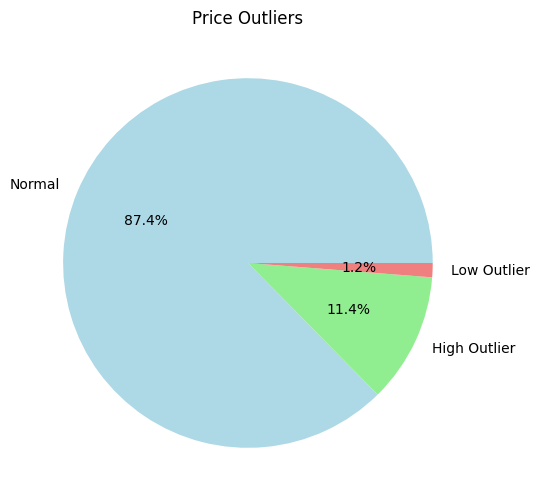

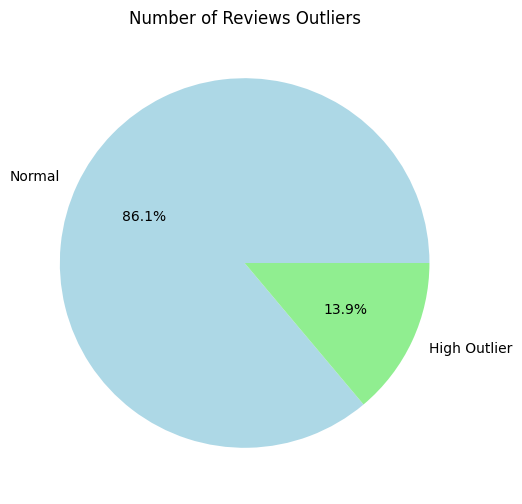

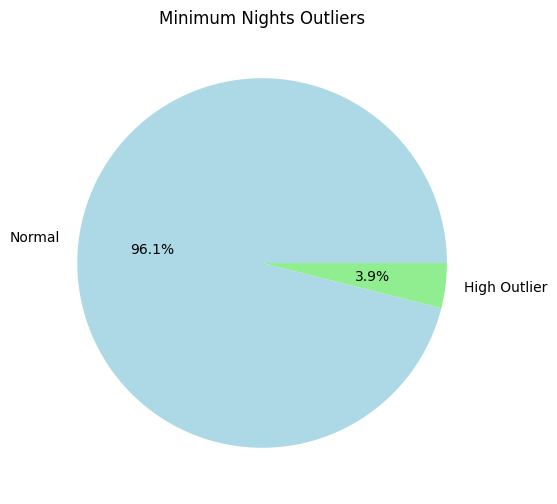

,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,number_of_host_assets,days_available_in_a_year,number_of_reviews_ltm
0,27886,"Romantic, stylish B&B houseboat in canal district",97647,Flip,Centrum-West,52.38761,4.89188,Private room,132.0,3,302,1.85,1,53,28
1,28871,Comfortable double room,124245,Edwin,Centrum-West,52.36775,4.89092,Private room,78.0,2,710,3.93,2,130,93
2,29051,Comfortable single / double room,124245,Edwin,Centrum-Oost,52.36584,4.89111,Private room,70.0,2,822,4.74,2,121,86
3,44391,Quiet 2-bedroom Amsterdam city centre apartment,194779,Jan,Centrum-Oost,52.37168,4.91471,Entire home/apt,248.0,3,42,0.23,1,0,0
4,47061,Charming apartment in old centre,211696,Ivar,De Baarsjes - Oud-West,52.36786,4.87458,Entire home/apt,120.0,2,203,1.13,1,66,5


In [ ]:
def plot_iqr_outlier_pie(df, column, title=None): #Define a function based on IQR classification
    Q1 = df_cleaned[column].quantile(0.25)
    Q3 = df_cleaned[column].quantile(0.75)
    IQR = Q3 - Q1

    def classify(val): #Classify each value as low, high, or normal
        if val > Q3 + 1.5 * IQR:
            return 'High Outlier'
        elif val < Q1 - 1.5 * IQR:
            return 'Low Outlier'
        else:
            return 'Normal'

    categories = df_cleaned[column].apply(classify) #Apply classification to the column
    counts = categories.value_counts()

   #Prepare data for the pie chart
    plt.figure(figsize=(6,6))
    plt.pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        colors= ['lightblue', 'lightgreen', 'lightcoral'])
    plt.title(title or f"{column} Outliers")
    plt.show()

plot_iqr_outlier_pie(df_cleaned, 'price', "Price Outliers") #Create the pie chart
plot_iqr_outlier_pie(df_cleaned, 'number_of_reviews', "Number of Reviews Outliers")
plot_iqr_outlier_pie(df_cleaned, 'minimum_nights', "Minimum Nights Outliers")

df_cleaned.head()

##**עמודות חדשות**

In [ ]:
def price_category(price): #Categorize price as low\medium\high
    if price < 100:
        return "Low"
    elif 100 <= price <= 300:
        return "Medium"
    else:
        return "High"

def host_experience(reviews): #Categorize host experience
    if reviews == 0:
        return "New host"
    elif 1 <= reviews <= 50:
        return "Intermediate host"
    else:
        return "Experienced host"

def availability_cat(days): #Categorize availability
    if days == 0:
        return "Not available"
    elif 0 < days <= 90:
        return "Low availability"
    elif  90 < days <= 180:
        return "Medium availability"
    elif 180 < days <= 365:
        return "High availability"

#Creating new columns
df_cleaned['price_category'] = df_cleaned['price'].apply(price_category)
df_cleaned['availability'] = df_cleaned['days_available_in_a_year'].apply(availability_cat)
df_cleaned['host_experience'] = df_cleaned['number_of_reviews'].apply(host_experience)
df_cleaned['active_property'] = df_cleaned['reviews_per_month'].apply(lambda x: "Active" if x > 0 else "Inactive")
df_cleaned.head()


,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,number_of_host_assets,days_available_in_a_year,number_of_reviews_ltm,price_category,availability,host_experience,active_property
0,27886,"Romantic, stylish B&B houseboat in canal district",97647,Flip,Centrum-West,52.38761,4.89188,Private room,132.0,3,302,1.85,1,53,28,Medium,Low availability,Experienced host,Active
1,28871,Comfortable double room,124245,Edwin,Centrum-West,52.36775,4.89092,Private room,78.0,2,710,3.93,2,130,93,Low,Medium availability,Experienced host,Active
2,29051,Comfortable single / double room,124245,Edwin,Centrum-Oost,52.36584,4.89111,Private room,70.0,2,822,4.74,2,121,86,Low,Medium availability,Experienced host,Active
3,44391,Quiet 2-bedroom Amsterdam city centre apartment,194779,Jan,Centrum-Oost,52.37168,4.91471,Entire home/apt,248.0,3,42,0.23,1,0,0,Medium,Not available,Intermediate host,Active
4,47061,Charming apartment in old centre,211696,Ivar,De Baarsjes - Oud-West,52.36786,4.87458,Entire home/apt,120.0,2,203,1.13,1,66,5,Medium,Low availability,Experienced host,Active


#**Part 3 - Data Analysis**

##**ניתוח חד-משתני**

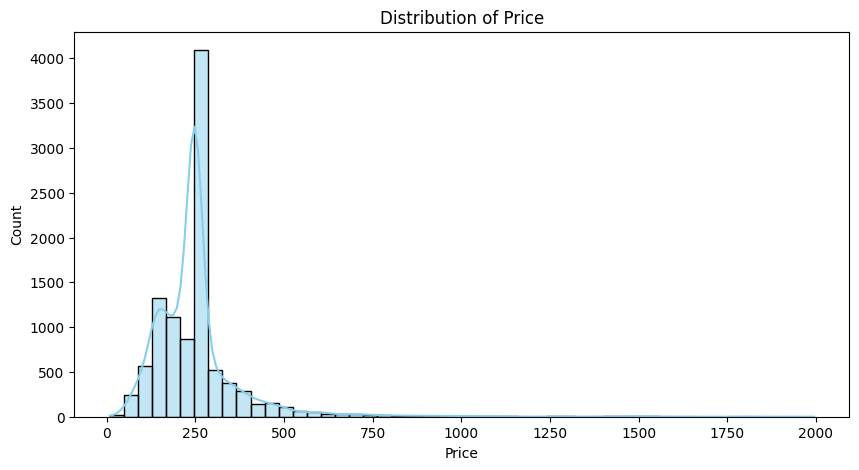

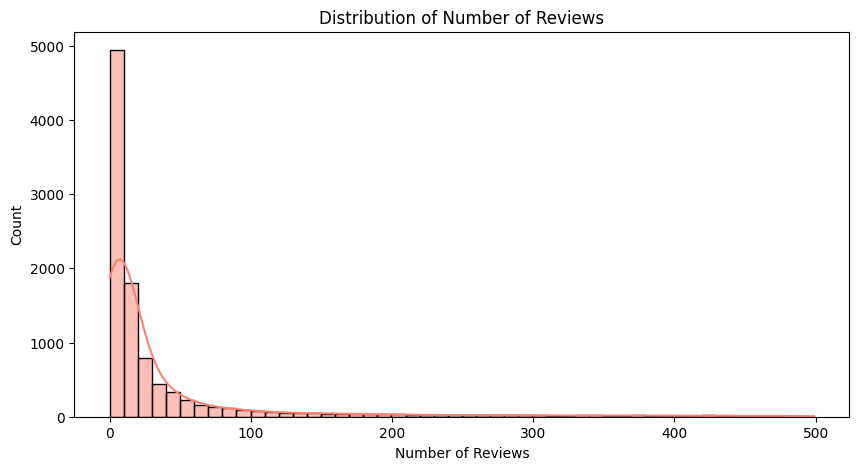

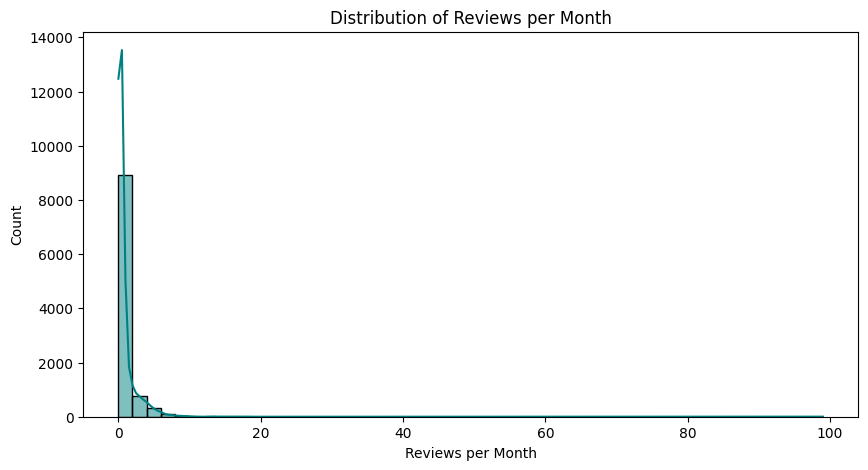

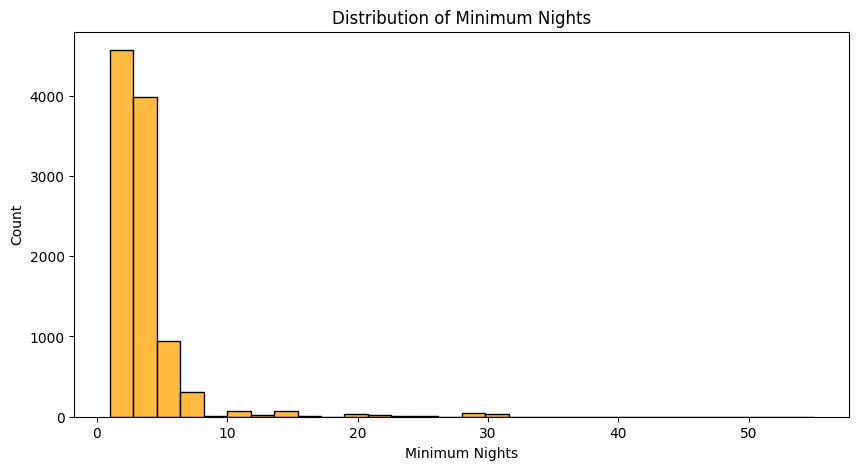

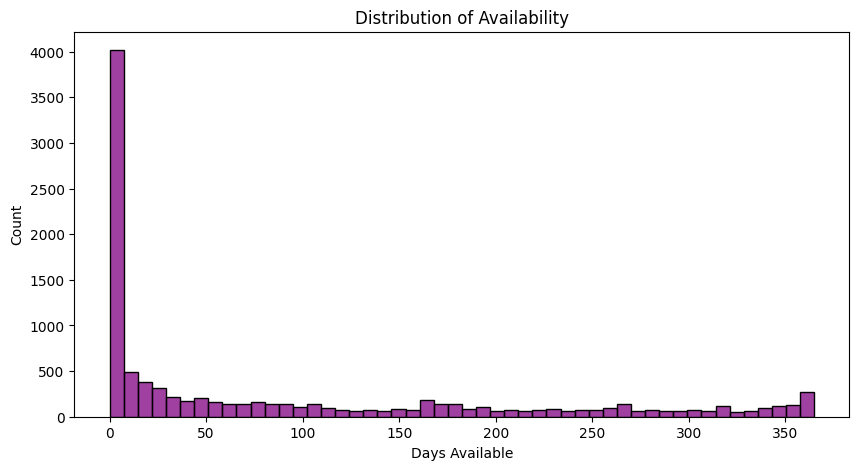

In [ ]:
#Price
plt.figure(figsize=(10, 5))
sns.histplot(df_cleaned[df_cleaned['price'] < 2000]['price'], bins=50, kde=True, color='skyblue')
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

#Number of Reviews
plt.figure(figsize=(10, 5))
sns.histplot(df_cleaned[df_cleaned['number_of_reviews'] < 500]['number_of_reviews'], bins=50, kde=True, color='salmon')
plt.title("Distribution of Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Count")
plt.show()

#Reviews per Month
plt.figure(figsize=(10, 5))
sns.histplot(df_cleaned['reviews_per_month'].dropna(), bins=50, kde=True, color='teal')
plt.title("Distribution of Reviews per Month")
plt.xlabel("Reviews per Month")
plt.ylabel("Count")
plt.show()

#Minimum Nights
plt.figure(figsize=(10, 5))
sns.histplot(df_cleaned[df_cleaned['minimum_nights'] < 60]['minimum_nights'], bins=30, kde=False, color='orange')
plt.title("Distribution of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.ylabel("Count")
plt.show()

#Days Available in a Year
plt.figure(figsize=(10, 5))
sns.histplot(df_cleaned['days_available_in_a_year'], bins=50, kde=False, color='purple')
plt.title("Distribution of Availability")
plt.xlabel("Days Available")
plt.ylabel("Count")
plt.show()


<div dir="rtl">  

Price:
התפלגות לא סימטרית: רוב הנכסים זולים יחסית - מרוכזים בטווח של  0-300, אך יש מחירים חריגים גבוהים יותר.

Number of Reviews:
רוב הנכסים עם פחות מ־100 ביקורות.
קיים מיעוט קטן עם מאות ביקורות, שמעיד על נכסים מאוד פופולריים או ותיקים.

Reviews per Month:
יש פיזור רחב, אך רוב הנכסים מקבלים פחות מ־2 ביקורות בחודש.

Minimum Nights:
מספר הנכסים המאפשרים שהייה מינימלית של 1-3 לילות גבוה בהרבה מאשר אלו הדורשים מספר לילות מינימלי גבוה יותר.

Days Available in a Year:  

ניתן לראות בגרף שלוש נקודות עיקריות:

0 ימים - נכסים שאינם זמינים כלל.

כ-180 ימים - נכסים הזמינים באופן חלקי.

365 ימים - נכסים זמינים כל השנה.

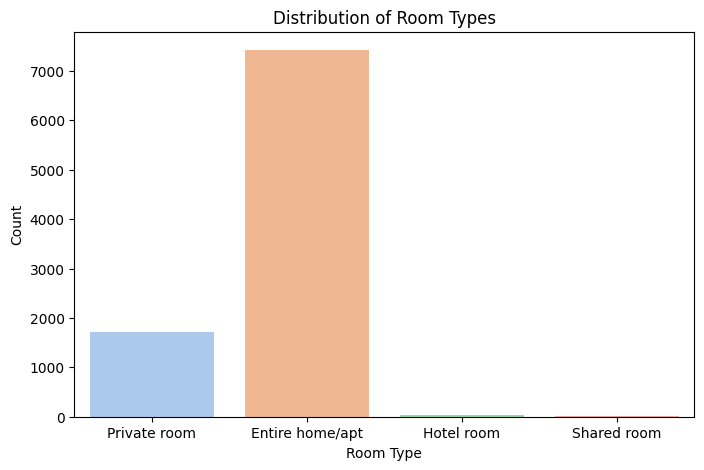

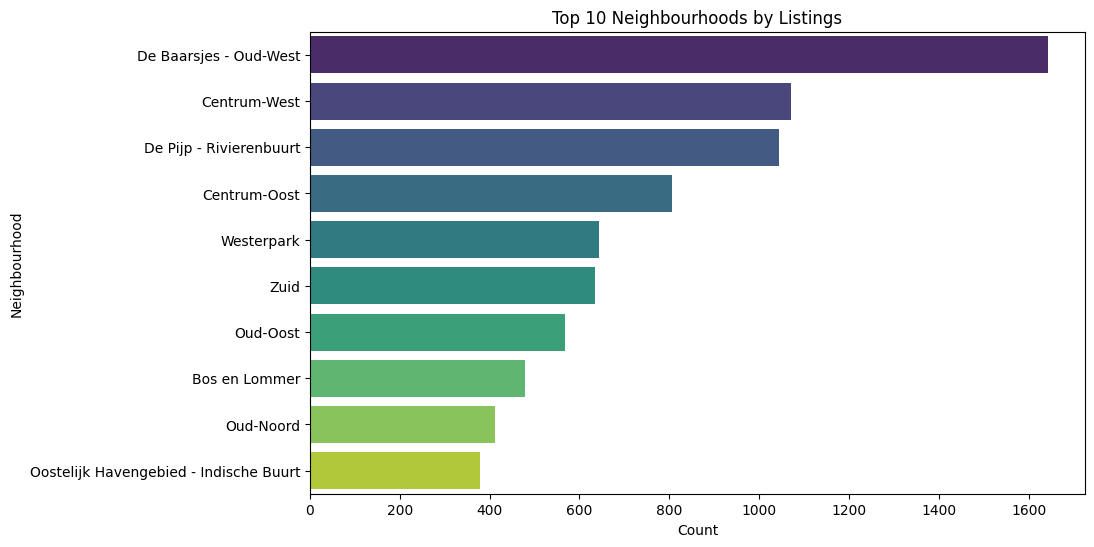

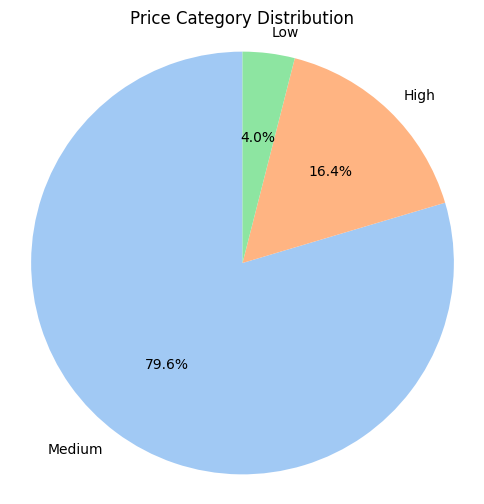

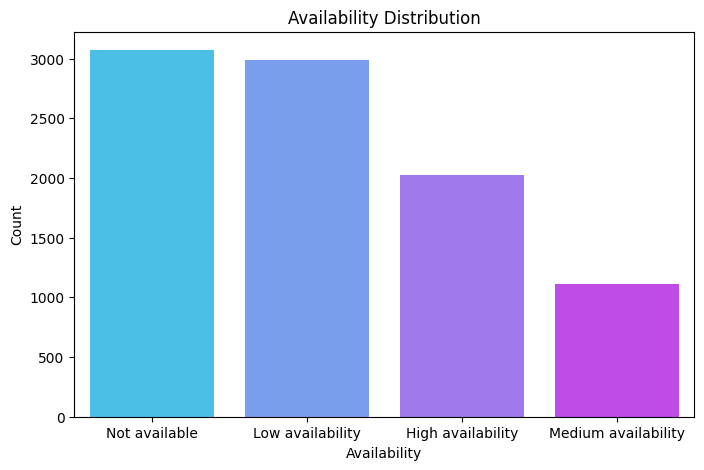

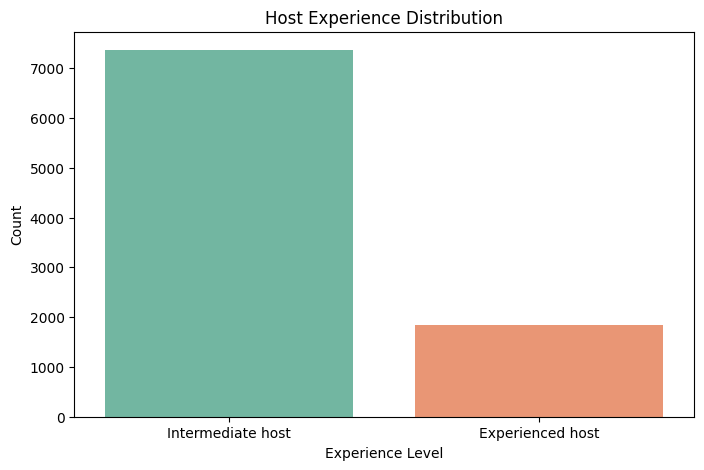

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
df_active = df_cleaned[df_cleaned['active_property'] == "Active"]

#Room Type
plt.figure(figsize=(8,5))
sns.countplot(data=df_active, x='room_type', palette='pastel')
plt.title("Distribution of Room Types")
plt.xlabel("Room Type")
plt.ylabel("Count")
plt.show()

#Neighbourhood
top_neigh = df_active['neighbourhood'].value_counts().nlargest(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_neigh.values, y=top_neigh.index, palette='viridis')
plt.title("Top 10 Neighbourhoods by Listings")
plt.xlabel("Count")
plt.ylabel("Neighbourhood")
plt.show()

#Price Category
price_cat_counts = df_active['price_category'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(price_cat_counts.values, labels=price_cat_counts.index, autopct='%1.1f%%',
        startangle=90, colors=sns.color_palette('pastel'))
plt.title("Price Category Distribution")
plt.axis('equal')
plt.show()

#Availability
plt.figure(figsize=(8,5))
sns.countplot(data=df_active, x='availability', order=df_active['availability'].value_counts().index, palette='cool')
plt.title("Availability Distribution")
plt.xlabel("Availability")
plt.ylabel("Count")
plt.show()

#Host Experience
plt.figure(figsize=(8,5))
sns.countplot(data=df_active, x='host_experience', order=df_active['host_experience'].value_counts().index, palette='Set2')
plt.title("Host Experience Distribution")
plt.xlabel("Experience Level")
plt.ylabel("Count")
plt.show()

 <div dir="rtl">   

Room Type:   ניתן להבחין כי רוב הדירות הן או חדר פרטי או בית שלם, ומעט מאוד בדורמס או במלון.
הדפוס שניתן לזהות כן הוא שהאורחים מעדיפים פרטיות כמעט מלאה.

Neighbourhood: ריכוז גדול של דירות באזורים מרכזיים
דפוס: Airbnb מרוכז במרכז העיר יותר מאשר בפריפריה.

Price Category: רוב הנכסים נופלים בקטגוריות Low/Medium.
דפוס: השוק די נגיש, ויש מעט נכסים יוקרתיים מאוד.  

Availability: הרבה דירות תחת Not Available.
דפוס: יש "שוק נסתר" – הרבה נכסים רשומים אבל לא זמינים להזמנה בפועל.

Host Experience: הרבה מארחים עם ניסיון בינוני או גבוה (יותר מ־50 ביקורות).
דפוס: השוק נשלט ע"י מארחים מנוסים ולא חדשים.    
   
מסקנות:   

השוק לא סימטרי – הרבה דירות עם מעט ביקורות / מעט זמינות, מעט דירות שמחזיקות את רוב הפעילות.

Airbnb באמסטרדם הוא שוק שמתרכז במרכז העיר, עם מחירים בינוניים.

קיימת הטעיה בנתונים – הרבה נכסים לא פעילים בפועל, ולכן חובה לסנן לפי Active.

רוב המארחים מנוסים – כלומר מדובר לא רק באנשים פרטיים, אלא לעיתים גם בשחקנים מקצועיים.

##**ניתוח דו ורב משתני**

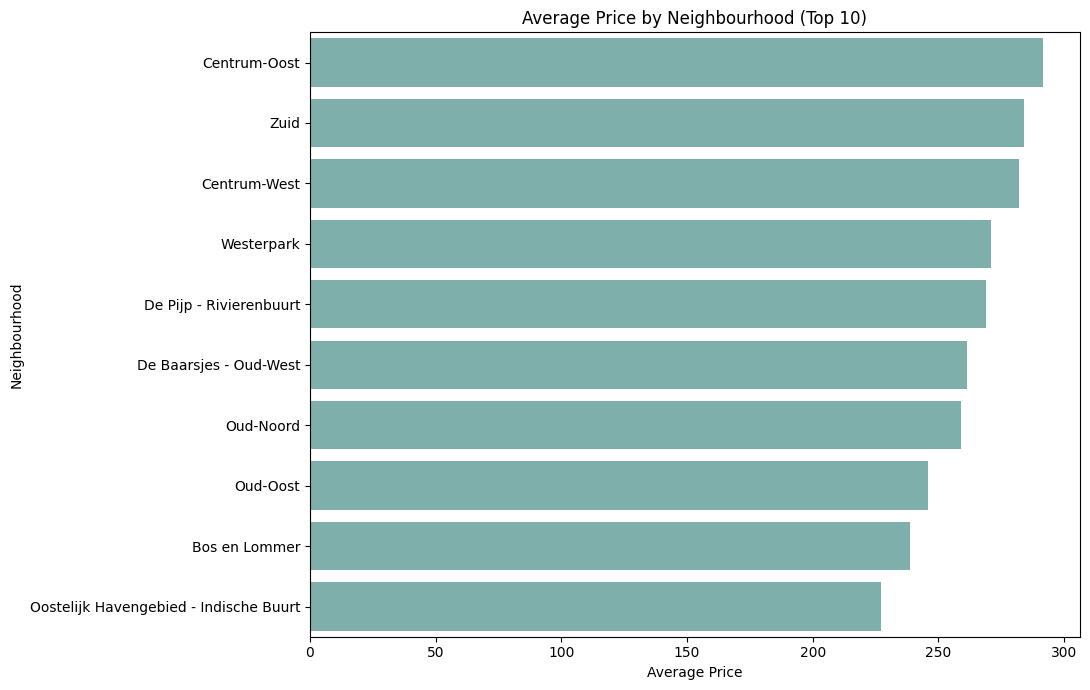

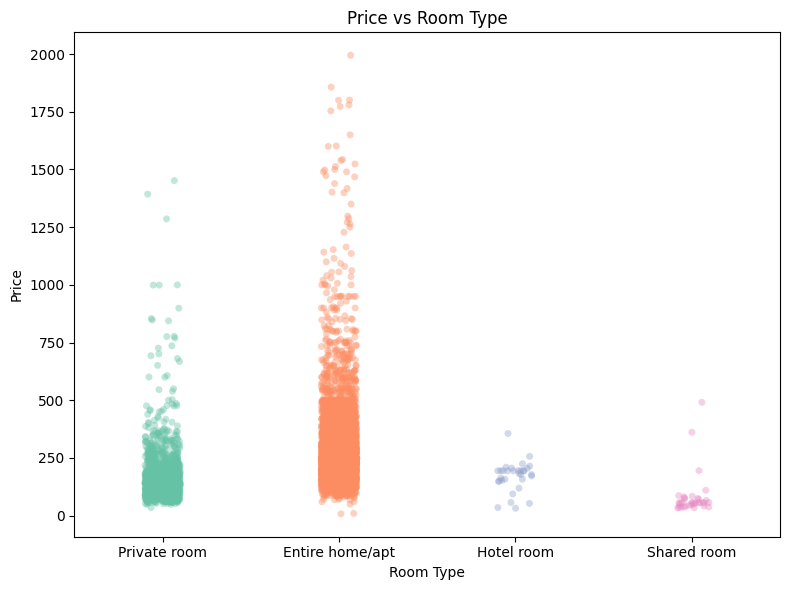

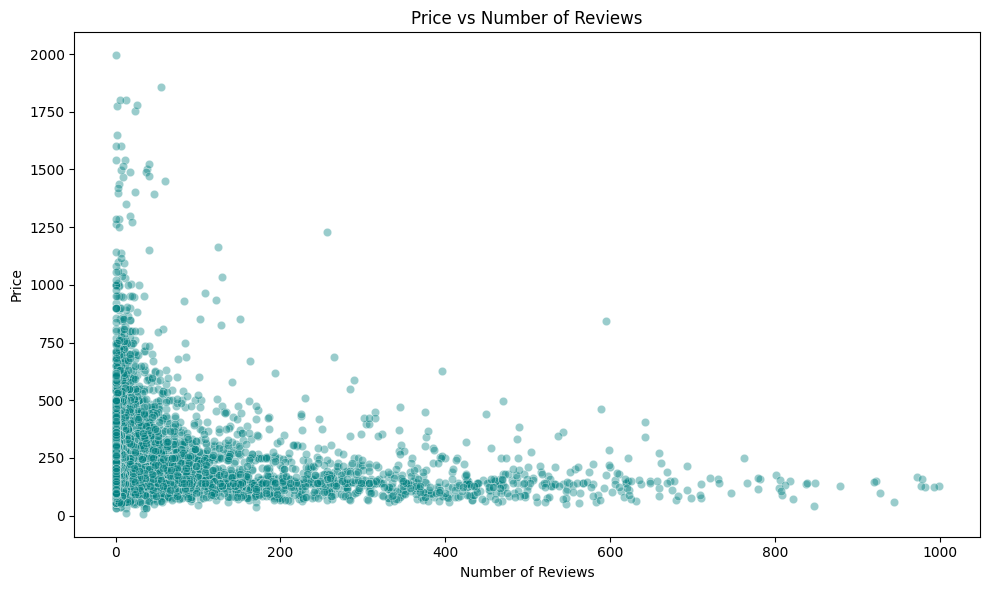

In [ ]:
#Filter the top 10 neighborhoods by number of listings, then calculate the average price in each
top10_neigh = df_cleaned['neighbourhood'].value_counts().nlargest(10).index
subset = df_cleaned[df_cleaned['neighbourhood'].isin(top10_neigh)]
mean_prices = (subset.groupby('neighbourhood')['price'].mean().sort_values(ascending=False))

# Plot: Bar chart of average price by neighborhood (top 10)
plt.figure(figsize=(11, 7))
sns.barplot(x=mean_prices.values, y=mean_prices.index, color="#76b7b2",errorbar=None)
plt.title("Average Price by Neighbourhood (Top 10)")
plt.xlabel("Average Price")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

#Plot: Stripplot of price by room type
plt.figure(figsize=(8, 6))
sns.stripplot(data=df_cleaned[df_cleaned['price'] < 2000],
    x='room_type',
    y='price',
    jitter=True,
    alpha=0.4,
    palette="Set2")
plt.title("Price vs Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

#Plot: Scatterplot showing relationship between price and number of reviews
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cleaned[(df_cleaned['price'] < 2000) & (df_cleaned['number_of_reviews'] < 1000)],
    x='number_of_reviews',
    y='price',
    alpha=0.4,
    color='teal')
plt.title("Price vs Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


<div dir="rtl">    

**מחיר לפי שכונה**

Centrum-Oost, Zuid, -Centrum-West נמצאות בראש - ולכן סביר שהמחירים בהן גבוהים יותר.

**מחיר לפי סוג חדר**

הגרף מציג מחירים לפי סוג חדר (מתחת ל־2000):

Entire home/apt: מגוון רחב של מחירים, כולל הגבוהים ביותר.

Private room: רוב המחירים נעים בין 100-400.

Hotel room: מרוכז סביב 150-250.

Shared room: מחירים נמוכים, לרוב מתחת ל־100.
  
**מחיר מול מספר ביקורות**

רוב המחירים הגבוהים מופיעים כשיש מעט ביקורות.
ככל שמספר הביקורות גדל — המחיר נוטה להיות נמוך יותר ומרוכז סביב 100-300.

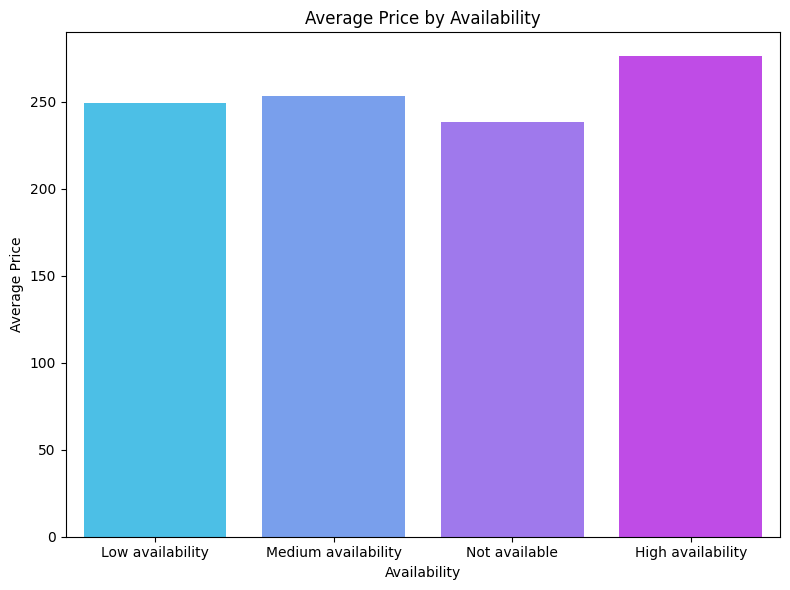

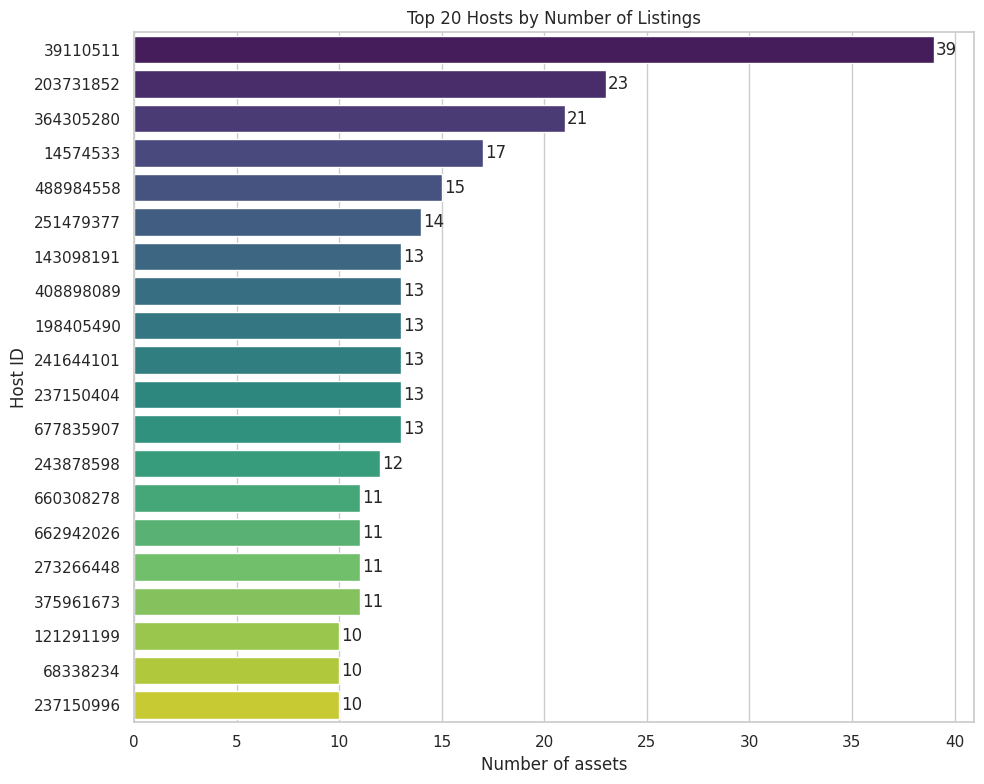

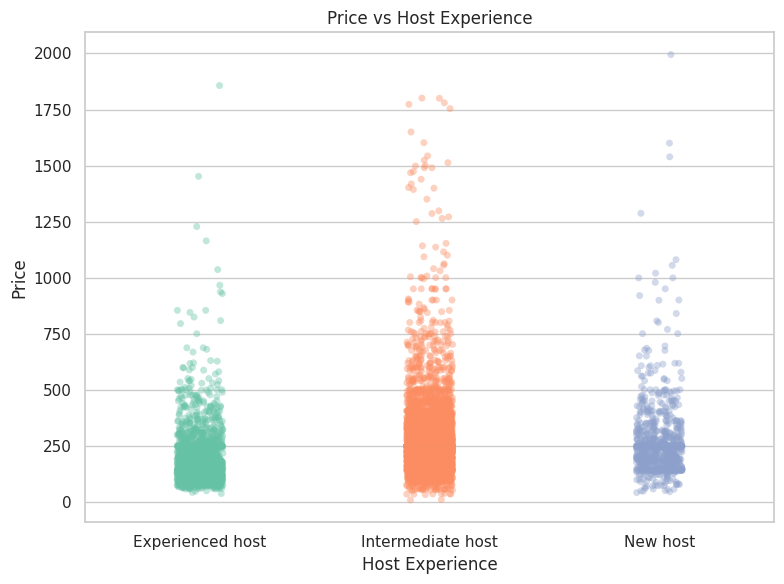

In [ ]:
#Average price by availability category
plt.figure(figsize=(8,6))
sns.barplot(data=df_cleaned[df_cleaned['price'] < 2000],x='availability',y='price',estimator=lambda x: x.mean(),errorbar=None,palette="cool")
plt.title("Average Price by Availability")
plt.xlabel("Availability")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()

#Determine listing key and compute number of listings per host
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 8)
listing_key = None
for cand in ["id", "listing_id", "listingID"]:
    if cand in df_cleaned.columns:
        listing_key = cand
        break
if listing_key:
    #Count unique listings per host if listing ID exists
    host_counts = (df_cleaned.dropna(subset=["host_id"]).groupby("host_id")[listing_key].nunique().reset_index(name="num_listings"))
else:
    #Count rows per host if no listing ID column found
    host_counts = (df_cleaned.dropna(subset=["host_id"]).groupby("host_id").size().reset_index(name="num_listings"))

#Prepare top 20 hosts with most listings
host_counts["num_listings"] = host_counts["num_listings"].astype(int)
top20 = host_counts.sort_values("num_listings", ascending=False).head(20).copy()
top20["host_id_str"] = top20["host_id"].astype(str)

#Horizontal barplot of top 20 hosts by number of listings
plt.figure(figsize=(10, 8))
sns.barplot(data=top20,x="num_listings",y="host_id_str",palette="viridis",errorbar=None)
plt.title("Top 20 Hosts by Number of Listings")
plt.xlabel("Number of assets")
plt.ylabel("Host ID")

#Add text labels with exact count
for i, v in enumerate(top20["num_listings"]):
    plt.text(v + 0.1, i, str(v), va="center")
plt.tight_layout()
plt.show()

#Plot: Stripplot of price by host experience
plt.figure(figsize=(8, 6))
sns.stripplot(data=df_cleaned[df_cleaned['price'] < 2000],x='host_experience',y='price',jitter=True,alpha=0.4,palette="Set2")
plt.title("Price vs Host Experience")
plt.xlabel("Host Experience")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

<div = dir = rtl>  

**מחיר מול זמינות**  

מחיר ממוצע גבוה יותר משויך לזמינות גבוהה, ואילו נכסים שאינם זמינים כלל מציגים את המחיר הממוצע הנמוך ביותר.

**טופ 20 מארחים עם הכי הרבה נכסים**

הגרף מציג את 20 המארחים המובילים לפי מספר הנכסים. המארח עם מזהה 39110511 בולט עם 39 נכסים, הרבה יותר מהשאר. שאר המארחים ברשימה מחזיקים בין 10 ל־23 נכסים. הפער בין המוביל לבין היתר משמעותי.

**מחיר מול ניסיון**

Experienced hosts: לרוב מתמחרים גבוה יותר, אך עם פיזור רחב מאוד של מחירים.

Intermediate hosts: נמצאים באמצע, עם טווח מחירים יחסית סביר.

New hosts: נוטים להציג מחירים נמוכים יותר.  




###**ניתוח לפי מיקום**

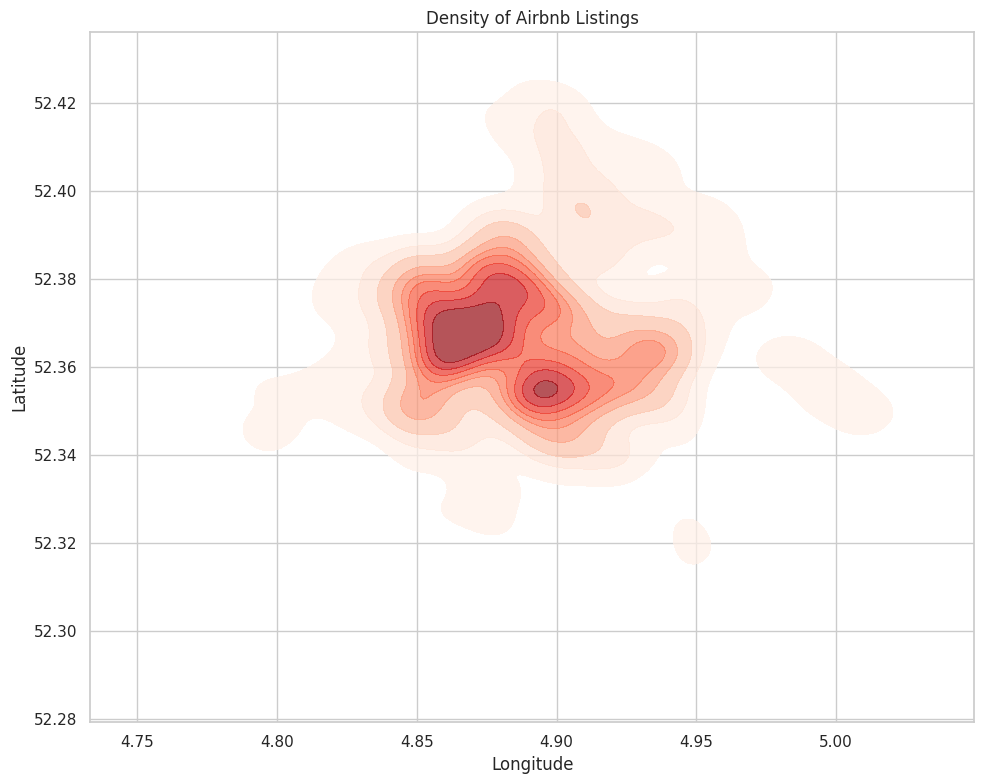

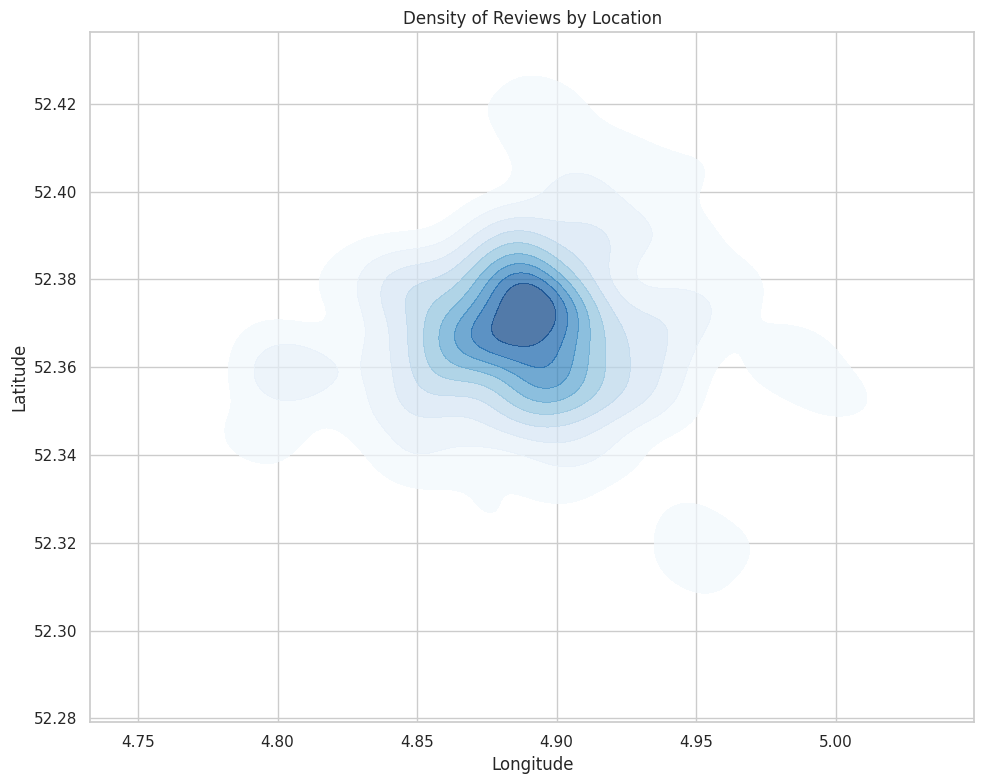

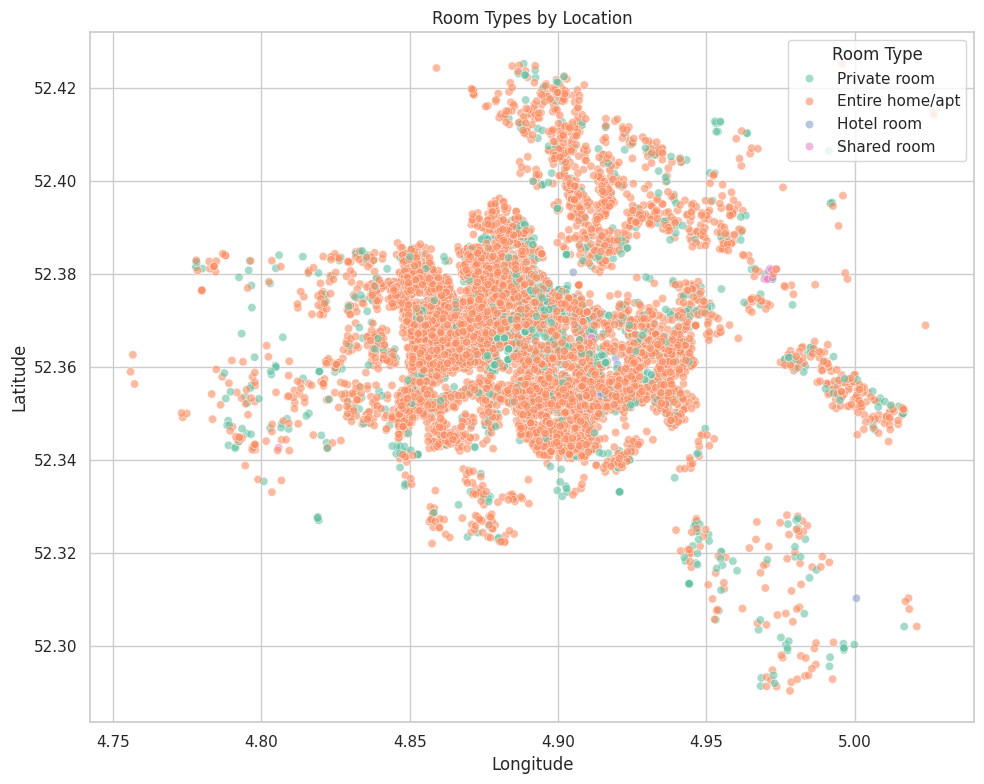

In [ ]:
#Heatmap of overall Airbnb listing density based on location
plt.figure(figsize=(10, 8))
sns.kdeplot(data=df_cleaned,
            x='longitude',
            y='latitude',
            fill=True,
            cmap="Reds",
            thresh=0.05,
            alpha=0.7)
plt.title("Density of Airbnb Listings")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

#Heatmap of review density by location
plt.figure(figsize=(10, 8))
sns.kdeplot(data=df_cleaned[df_cleaned['number_of_reviews'] > 0],
            x='longitude',
            y='latitude',
            weights=df_cleaned.loc[df_cleaned['number_of_reviews'] > 0, 'number_of_reviews'],
            fill=True,
            cmap="Blues",
            thresh=0.05,
            alpha=0.7)
plt.title("Density of Reviews by Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

#Scatterplot of room types by geographic location
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_cleaned[df_cleaned['price'] < 2000],
                x='longitude',
                y='latitude',
                hue='room_type',       # Color-coded by room type
                alpha=0.6,
                palette="Set2")
plt.title("Room Types by Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Room Type", loc="upper right")
plt.tight_layout()
plt.show()

<div = dir = rtl>  

**מסקנות ממפת צפיפות נכסים**

רוב הנכסים מתרכזים סביב מרכז אמסטרדם.

זה מעיד שהתיירים מחפשים להיות קרובים לאטרקציות התיירותיות (כיכר דאם, התעלות, מוזיאונים).

מבחינת מארחים תחרות גבוהה מאוד במרכז, קשה להתבלט.

בשכונות המרוחקות יש הרבה פחות דירות להשכרה.

מבחינת מארחים  פחות תחרות.
השוק באמסטרדם מרוכז מאוד גיאוגרפית – Airbnb זה בעיקר תופעה עירונית במרכז ולא בפרברים.

**מסקנות ממפת הביקורות ביחס למיקום**

האזורים במרכז לא רק שיש בהם הכי הרבה דירות אלא גם שם נרשמות הכי הרבה ביקורות (הכי הרבה פעילות כנראה).

באזורים מרוחקים יותר כמעט ואין ביקורות כלומר פחות תיירות ופחות שימוש בפועל.


**מסקנות ממפת סוג החדר ביחס למיקום**

במרכז העיר כנראה נראה ריכוז של בית שלם/דירה (תיירים שרוצים יותר פרטיות).

בפריפריה עשויים להופיע יותר חדרים פרטיים (תיירים בתקציב נמוך או שרוצים   חוויה מקומית יותר).

Shared room או Hotel room יהיו כנראה פחות שכיחים.

##**בדיקת השערות**

**"בתים שלמים יקרים יותר מחדרים פרטיים או משותפים"**

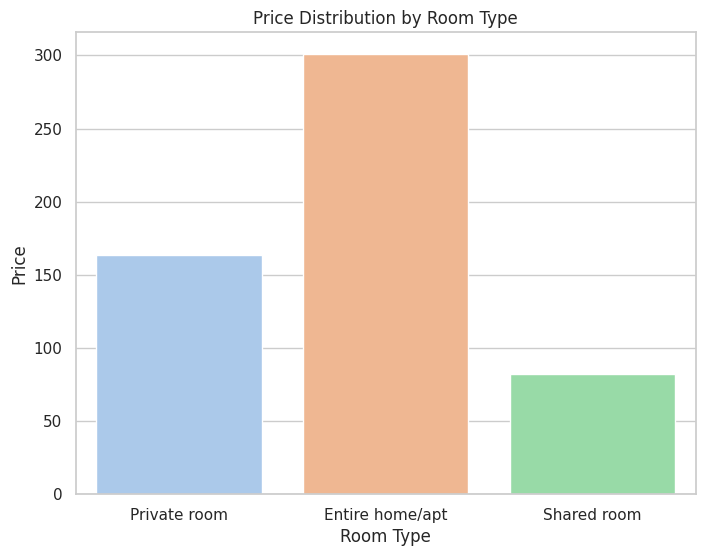

In [ ]:
df_filtered = df_cleaned[df_cleaned['room_type'] != 'Hotel room']
plt.figure(figsize=(8,6))
sns.barplot(data=df_filtered, x='room_type', y='price', palette='pastel',errorbar=None)
plt.title("Price Distribution by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price")
plt.show()

כפי שניתן לראות בגרף המוצג, השערה זה נכונה. מחיר בתים שלמים יקר יותר מחדרים משותפים או פרטיים.

**"לרישומים עם יותר ביקורות יש זמינות גבוהה יותר"**

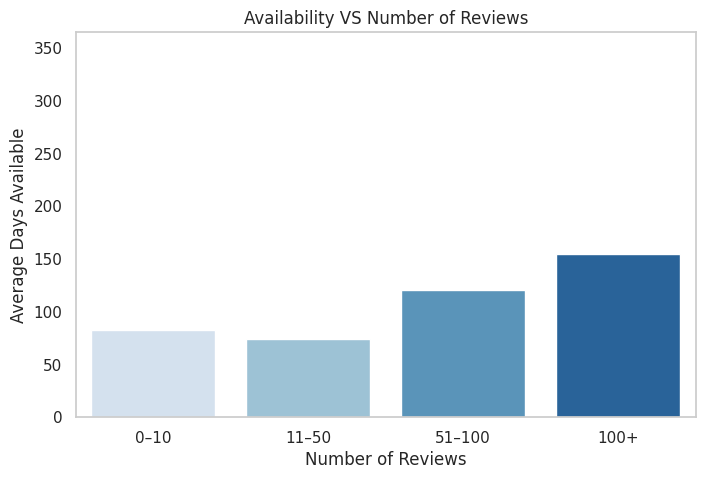

In [ ]:
x_labels = ["0–10", "11–50", "51–100", "100+"]
y_values = [
    df_cleaned[df_cleaned["number_of_reviews"] <= 10]["days_available_in_a_year"].mean(),
    df_cleaned[(df_cleaned["number_of_reviews"] > 10) & (df_cleaned["number_of_reviews"] <= 50)]["days_available_in_a_year"].mean(),
    df_cleaned[(df_cleaned["number_of_reviews"] > 50) & (df_cleaned["number_of_reviews"] <= 100)]["days_available_in_a_year"].mean(),
    df_cleaned[df_cleaned["number_of_reviews"] > 100]["days_available_in_a_year"].mean()]

plt.figure(figsize=(8, 5))
sns.barplot(x=x_labels, y=y_values, palette="Blues")
plt.title("Availability VS Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Average Days Available")
plt.ylim(0, 365)
plt.grid(axis="y")
plt.show()

מהגרף ניתן להסיק שככל שמספר הביקורות עולה, יש זמינות גבוהה יותר. לכן ההשערה נכונה.

**"מספר נכסים של המארח משפיע על התמחור"**

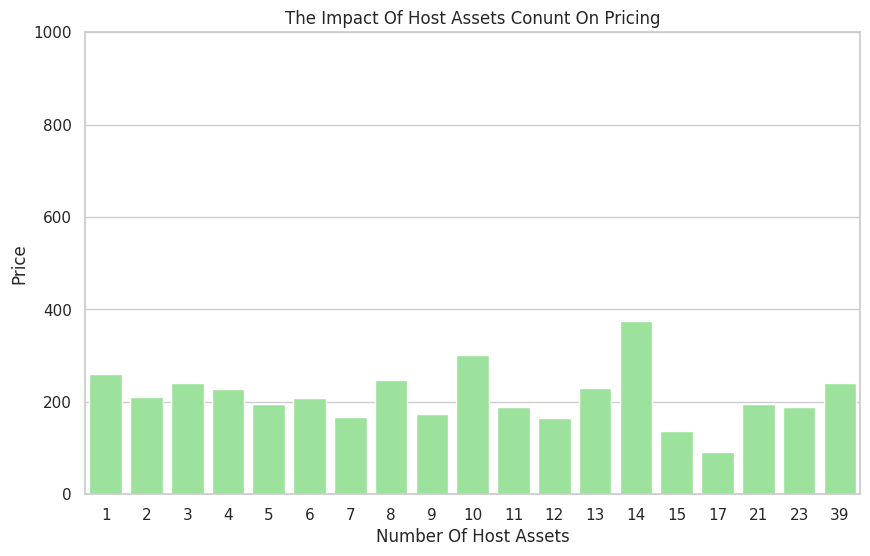

    number_of_host_assets  count_of_hosts   avg_price
0                       1            8351  259.841516
1                       2             734  209.664169
2                       3             261  241.421456
3                       4             132  226.973485
4                       5             120  194.891667
5                       6              96  208.546875
6                       7              63  166.619048
7                       8              40  246.375000
8                       9              36  172.902778
9                      10              50  301.150000
10                     11              44  189.715909
11                     12              12  164.041667
12                     13              78  230.692308
13                     14              14  374.714286
14                     15              15  137.400000
15                     17              17   92.176471
16                     21              21  194.785714
17                     23   

In [ ]:
filtered_df = df_cleaned[df_cleaned['price'] < 2000]
plt.figure(figsize=(10, 6))
sns.barplot(data=filtered_df, x='number_of_host_assets', y='price', color='lightgreen', errorbar=None)
plt.title('The Impact Of Host Assets Conunt On Pricing')
plt.ylim(0, 1000)
plt.xlabel('Number Of Host Assets')
plt.ylabel('Price')
plt.show()

summary = filtered_df.groupby("number_of_host_assets").agg(count_of_hosts=("id", "count"), avg_price=("price", "mean")).reset_index()
print(summary)

מהנתונים עולה כי מספר הנכסים של המארח לא בהכרח משפיע על התמחור.  
ביצענו סינון של מחירים חריגים מעל 2000.   
לרוב המארחים יש נכס אחד בלבד, כאשר ממוצע המחירים עומד על 259.  
ישנם מיעוט של 39 מארחים המחזיקים ב-39 נכסים, והממוצע אצלם דווקא נמוך יחסית ועומד על 241.  
לסיכום, אין כאן דפוס ברור: מספר הנכסים של מארח לא משפיע באופן עקבי על המחיר.

###**שאלות**

**שאלה 1**  
מהן השכונות הפופולריות ביותר להשכרות  Airbnb בעיר שנבחרה?  
כיצד משתנים המחירים
והזמינות לפי שכונה?

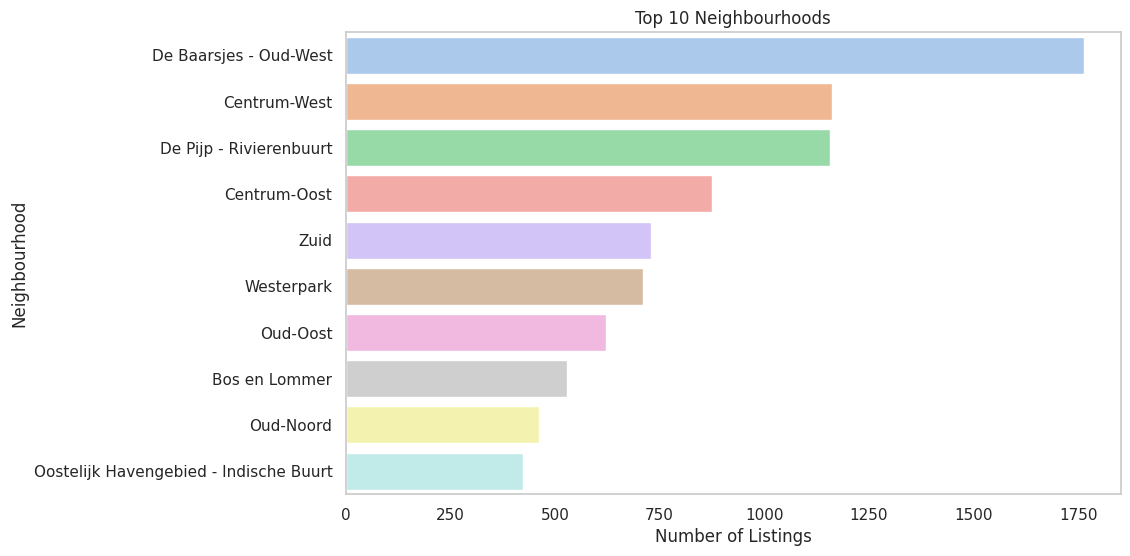

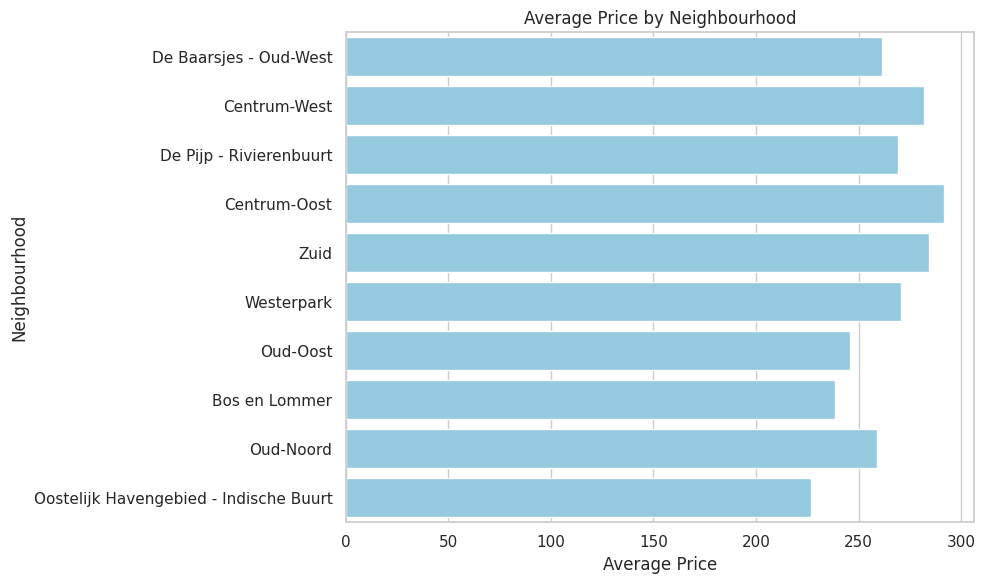

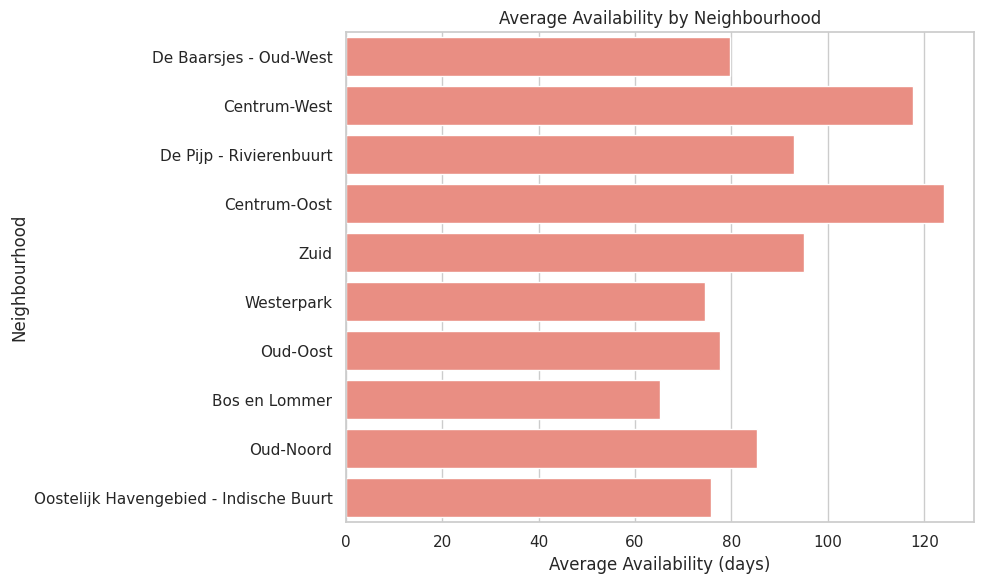

In [ ]:
#Top 10 neighbourhoods by number of listings
top_neighbourhoods = df_cleaned["neighbourhood"].value_counts().head(10).index
top_df = df_cleaned[df_cleaned["neighbourhood"].isin(top_neighbourhoods)]

#Number of listings per top neighbourhood
plt.figure(figsize=(10, 6))
sns.countplot(data=top_df, y="neighbourhood", order=top_neighbourhoods, palette="pastel")
plt.title("Top 10 Neighbourhoods")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")
plt.grid(axis='x')
plt.show()

#Calculate average price and availability for each neighbourhood
mean_values_by_neighbourhood = top_df.groupby("neighbourhood")[["price", "days_available_in_a_year"]].mean().loc[top_neighbourhoods]
neighbourhood_index = np.arange(len(mean_values_by_neighbourhood))

#Average price per neighbourhood
plt.figure(figsize=(10, 6))
sns.barplot(data=mean_values_by_neighbourhood, x="price", y="neighbourhood", color="skyblue")
plt.title("Average Price by Neighbourhood")
plt.xlabel("Average Price")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

#Average availability per neighbourhood
plt.figure(figsize=(10, 6))
sns.barplot(data=mean_values_by_neighbourhood, x="days_available_in_a_year", y="neighbourhood", color="salmon")
plt.title("Average Availability by Neighbourhood")
plt.xlabel("Average Availability (days)")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

**TOP 10-**  
כדי לזהות את השכונות הפופולריות ביותר, בדקנו את מספר הביקורות הכולל בכל שכונה.
קריטריון זה נבחר מפני שמספר הביקורות משקף לא רק את כמות הנכסים הרשומים, אלא גם את הביקוש בפועל מצד האורחים.  

לאחר מכן, על מנת לבדוק כיצד משתנים המחירים והזמינות לפי שכונה הצגנו גרף נוסף.  
מניתוח הגרף עולה כי בשכונות היותר פופולריות  
(Centrum West, Centrum Oost)  
 .ממוצע המחירים גבוהה משאר השכונות, אך גם הזמינות יחסית גבוהה  
ובנוסף ניתן לראות שהמחירים בשכונות הפופולריות עומדים בממוצע על כ-240 פר לילה- לא זול במיוחד.
________________________________________________________________________________

**שאלה 2**  
האם קיימים דפוסים או מגמות בנוגע לסוגי הנכסים שמושכרים דרך  ? Airbnbהאם סוגים
מסוימים של נכסים פופולריים יותר או יקרים יותר מאחרים?

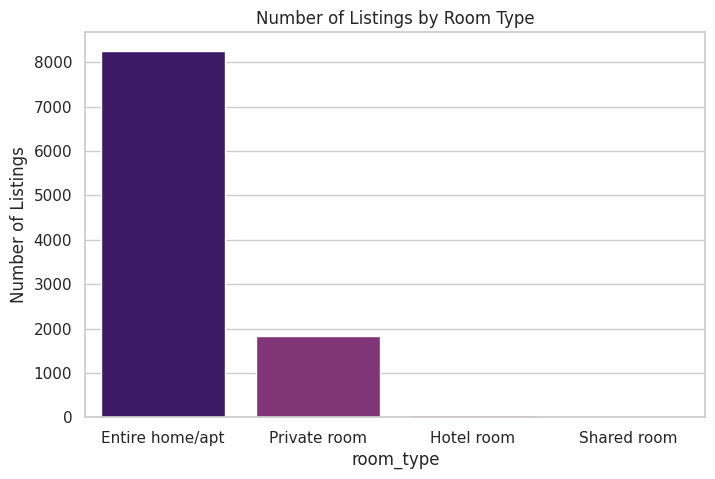

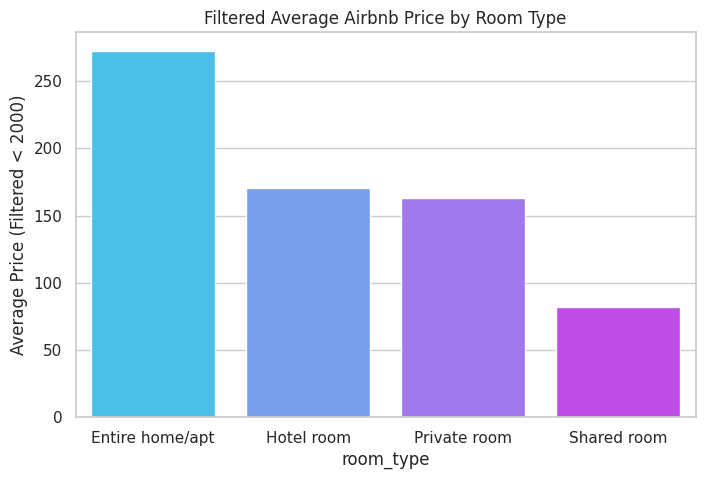

In [ ]:
#Count the number of listings by room type
room_counts = df_cleaned['room_type'].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=room_counts.index, y=room_counts.values, palette="magma")
plt.ylabel("Number of Listings")
plt.title("Number of Listings by Room Type")
plt.show()

#Calculate average price by room type
filtered_df = df_cleaned[df_cleaned["price"] < 2000]
room_price = filtered_df.groupby('room_type')['price'].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=room_price.index, y=room_price.values, palette="cool")
plt.ylabel("Average Price (Filtered < 2000)")
plt.title("Filtered Average Airbnb Price by Room Type")
plt.show()


בגרף הראשון הצגנו את התפלגות הנכסים המושכרים, ניתן לראות כי הרוב המוחלט של הנכסים הם מסוג בית/דירה שלמה.  
ובהתאם לזה ניתן גם לראות שהמחיר ללילה של סוג הנכס הזה יקר מאוד ביחס לשאר סוגי הנכסים. (סיננו מחירים מעל 2000 על מנת שערכי קיצון לא ישנו את ההתפלגות).  
________________________________________________________________________________

**שאלה 3**  
האם יש גורמים שנראה שהם קשורים למחירים של השכרות ? Airbnb


בחלק הקודם של ההשערות, הצגנו את היחס בין המחיר לבין סוג החדר (השערה ראשונה- גרף 1) ובנוסף גם את היחס בין המחיר לבין מספר הנכסים של המארח (השערה שלישית- גרף 3).  
בנוסף בחלק של הניתוח דו ורב משתני הצגנו את היחס בין מחיר למיקום ואת היחס בין מחיר לביקורות.  

בשאלה זו נראה גורמים אחרים נוספים הקשורים למחיר.

,host_experience,price
0,Experienced host,199.270845
1,Intermediate host,263.165692
2,New host,267.386458


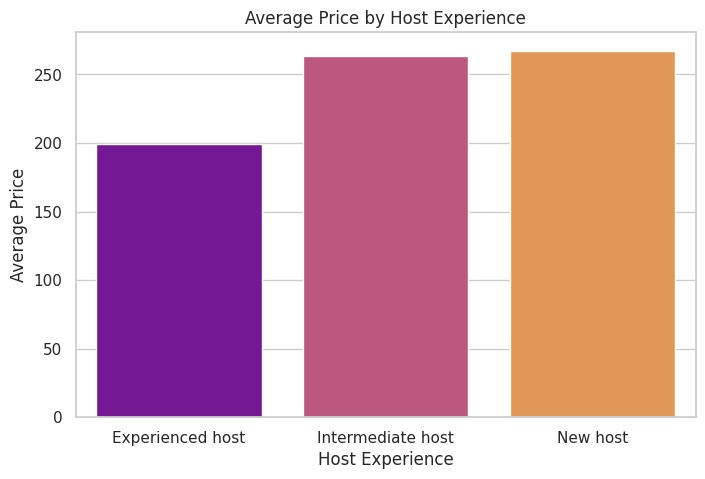

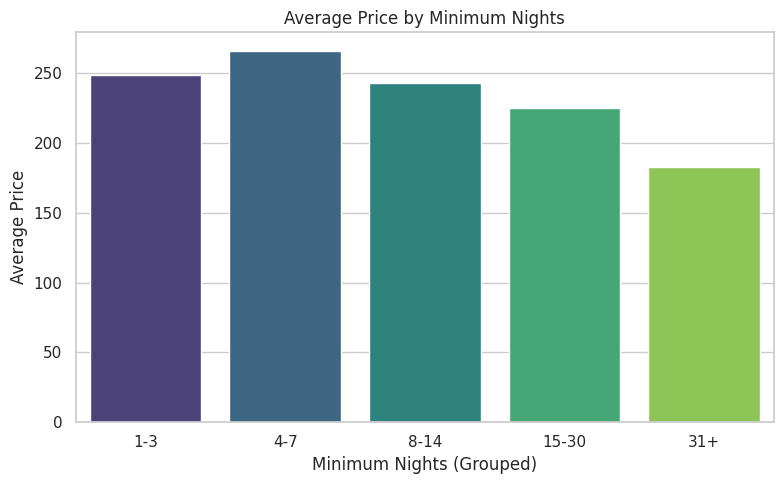

In [ ]:
#Calculate the average price for each host experience group
avg_price_by_exp = filtered_df.groupby('host_experience')['price'].mean().reset_index()
display(avg_price_by_exp)

plt.figure(figsize=(8, 5))
sns.barplot(data=avg_price_by_exp, x='host_experience', y='price', palette='plasma')
plt.title("Average Price by Host Experience")
plt.xlabel("Host Experience")
plt.ylabel("Average Price")
plt.show()

#Define a function to group minimum_nights into ranges
def get_min_nights_group(n):
    if n <= 3:
        return '1-3'
    elif n <= 7:
        return '4-7'
    elif n <= 14:
        return '8-14'
    elif n <= 30:
        return '15-30'
    else:
        return '31+'

#Group data using the defined function and calculate average price
min_nights_price_grouped = (
    filtered_df.groupby(filtered_df['minimum_nights'].apply(get_min_nights_group))['price'].mean()
)

#Define the correct order of the night groups for consistent plotting
order = ['1-3', '4-7', '8-14', '15-30', '31+']

#Average price by grouped minimum nights
plt.figure(figsize=(8, 5))
sns.barplot(x=min_nights_price_grouped.index, y=min_nights_price_grouped.values, palette='viridis', order=order)
plt.title("Average Price by Minimum Nights")
plt.xlabel("Minimum Nights (Grouped)")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()


בחרנו לבדוק בנוסף האם עוד שני גורמים משפיעים על המחיר:  
- Host Experience- ניסיון המארח   
לפי הגרף והטבלה, ניתן לראות שניסיון המארח אכן משפיע על המחיר.  
מארחים בעלי ניסיון לוקחים בממוצע ללילה כ-200 ומנגד, מאחרים חדשים חסרי ניסיון לוקחים יותר ממאחרים בעלי ניסיון ומחירים עומדים על כ-267 פר לילה.  
- Minimum Nights- מס' לילות מינימלי הנדרש להשכרת הנכס  
לפי הגרף והטבלה שהצגנו, ניתן לראות שאין שינוי מהותי בין המחיר למס' הלילות המינימלי אם מדובר במספר לילות בודדים, אך ככל שמספר הלילות עולה- המחיר פר לילה יורד.
________________________________________________________________________________

**שאלה 4**  
מהו האזור הטוב ביותר עבור מארח לרכוש נכס?

In [ ]:
filtered_df = df_cleaned[df_cleaned['price'] < 2000]
neighbourhood_stats = (
    filtered_df.groupby("neighbourhood")[["price", "days_available_in_a_year"]].mean()
    .sort_values(by=["price", "days_available_in_a_year"], ascending=[False, True]).reset_index())
display(neighbourhood_stats.head(10))

,neighbourhood,price,days_available_in_a_year
0,Zuid,278.414266,94.659808
1,Centrum-Oost,275.529748,124.217391
2,Centrum-West,269.494823,117.193270
3,De Pijp - Rivierenbuurt,266.711255,92.987013
4,De Baarsjes - Oud-West,261.212422,79.597277
5,Westerpark,250.647887,74.146479
6,Watergraafsmeer,248.329231,73.732308
7,Oud-Oost,245.689711,77.672026
8,IJburg - Zeeburgereiland,242.297436,90.420513
9,Oud-Noord,237.462963,84.154684


<div = dir = rtl>  

השכונות בראש הרשימה מציעות שילוב של תעריפים גבוהים וגם זמינות לא נמוכה מדי - אלו שכונות מצוינות להשקעה למארחים פוטנציאליים.
  
  
אם שכונה נמצאת גבוה אבל עם זמינות נמוכה מאוד - ייתכן שמדובר בבתים פרטיים, דירות וכו'.

________________________________________________________________________________

**שאלה 5**  
כיצד משתנים אורכי השהייה של השכרות  Airbnbלפי שכונה? האם יש שכונות שנוטות
למשוך שהיות קצרות או ארוכות יותר?

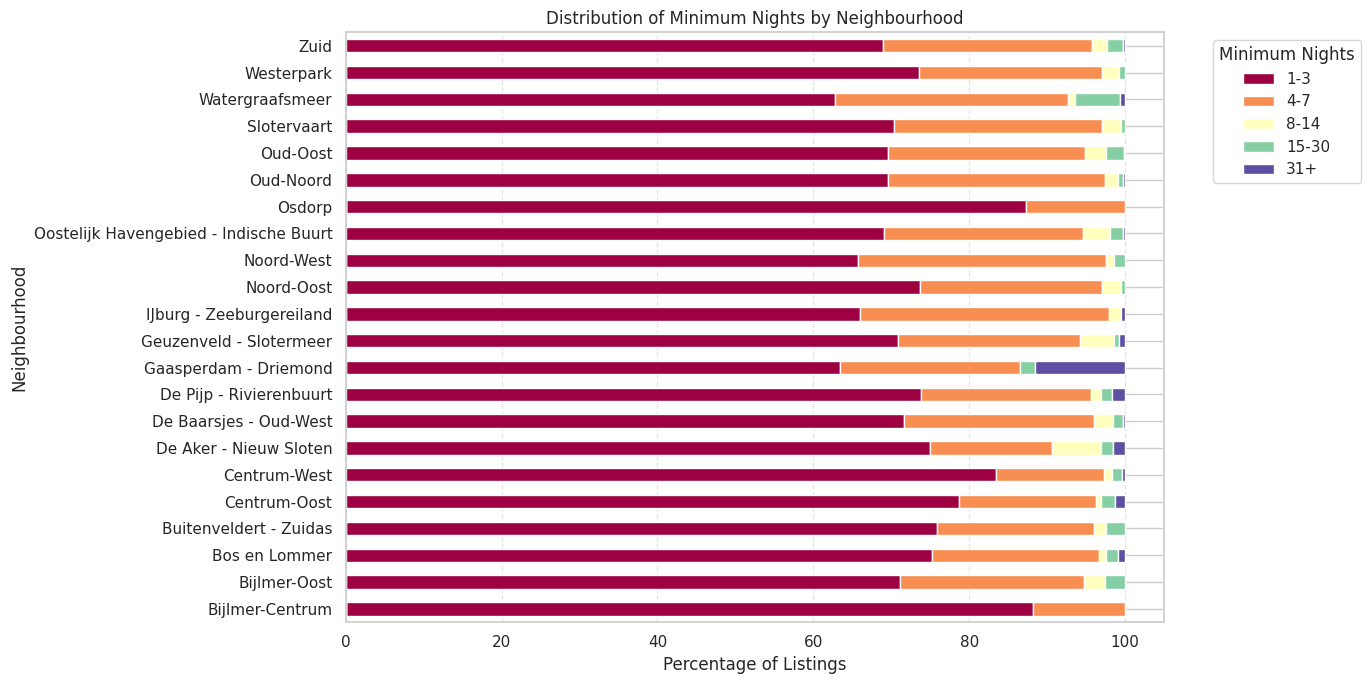

In [ ]:
#Create working copy and group column
df_temp = df_cleaned.copy()
df_temp['min_nights_group'] = df_temp['minimum_nights'].apply(get_min_nights_group)

#Define custom order
night_order = ['1-3', '4-7', '8-14', '15-30', '31+']

#Create pivot table of percentages
pivot_table = pd.crosstab(df_temp['neighbourhood'], df_temp['min_nights_group'], normalize='index') * 100

#Reorder columns
pivot_table = pivot_table[night_order]

#Plot
pivot_table.plot(kind='barh', stacked=True, figsize=(14, 7), colormap='Spectral')
plt.title('Distribution of Minimum Nights by Neighbourhood')
plt.xlabel('Percentage of Listings')
plt.ylabel('Neighbourhood')
plt.legend(title='Minimum Nights', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


<div = dir = rtl>    

שכונות תיירותיות ומרכזיות יותר מציגות שיעור גבוה של שהיות קצרות מאוד (1-3 לילות).

לעומת זאת, שכונות פריפריאליות יותר מציגות שיעור גבוה יותר של שהיות ארוכות. (15 לילות ומעלה)

________________________________________________________________________________

**שאלה 6**  
כיצד הדירוגים של השכרות  Airbnbביחס למחירים שלהן? האם השכרות יקרות יותר נוטות
לקבל דירוגים גבוהים יותר?

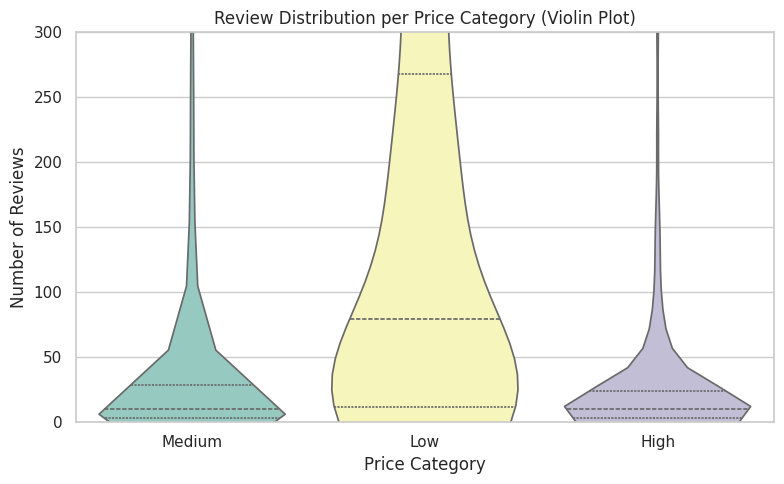

Low - Cheap listings
Medium - Moderately priced listing
High - Expensive listings


In [ ]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df_cleaned, x="price_category", y="number_of_reviews", palette="Set3", inner="quartile")
plt.title("Review Distribution per Price Category (Violin Plot)")
plt.xlabel("Price Category")
plt.ylabel("Number of Reviews")
plt.ylim(0, 300)
plt.tight_layout()
plt.show()

print("Low - Cheap listings\nMedium - Moderately priced listing\nHigh - Expensive listings")

מהגרף ניתן לראות כי דווקא הנכסים עם המחירים הזולים מקבלים את מספר הביקורות הגבוה ביותר וגם הפיזור הרחב ביותר של ביקורות.  
לעומת זאת, נכסים הנחשבים יקרים מקבלים הכי פחות ביקורות ולעיתים רבות כמעט ואין להם ביקורות כלל.  
________________________________________________________________________________

**שאלה 7**  
מצאו את מספר הביקורות הכולל ואת מספר הביקורות המרבי לפי כל קבוצת שכונות  
**העמודה neighbourhood_group (קבוצות שכונות)  
 היא עמודה ריקה אצלנו, אין לנו נתונים לצורך הצגת הפתרון**  
 _______________________________________________________________________________

**שאלה 8**  
מצאו את סוגי הנכס עם הכי הרבה ביקורות בקבוצות השכונות.  
**העמודה neighbourhood_group (קבוצות שכונות)  
 היא עמודה ריקה אצלנו, אין לנו נתונים לצורך הצגת הפתרון**  
 _______________________________________________________________________________

**שאלה 9**  
מצאו את מיקום הנכס הטוב ביותר עבור מטיילים על פי קריטריונים שונים כגון מחיר זול,
שכונה מבוקשת, הכי הרבה ביקורות ועוד

In [ ]:
#Copy the cleaned data
df_best = df_cleaned.copy()

#Sort by - most reviews, then availability, then lowest price
df_best_sorted = df_best.sort_values(by=['number_of_reviews', 'days_available_in_a_year', 'price'],
    ascending=[False, False, True])

#Select the top property
top_property = df_best_sorted.iloc[0]

#Display the information
print("Best Property:")
print(f"Neighbourhood: {top_property['neighbourhood']}")
print(f"Price: €{top_property['price']}")
print(f"Number of Reviews: {top_property['number_of_reviews']}")
print(f"Availability: {top_property['days_available_in_a_year']} days/year")
print(f"Location: Latitude = {top_property['latitude']}, Longitude = {top_property['longitude']}")


Best Property:
Neighbourhood: Osdorp
Price: €140.5
Number of Reviews: 4792
Availability: 360 days/year
Location: Latitude = 52.35831, Longitude = 4.80335


________________________________________________________________________________

**שאלה 10**  
מצאו ממוצעת מחירים בין קבוצות השכונות, כמות נכסים ועוד  
**העמודה neighbourhood_group (קבוצות שכונות)  
 היא עמודה ריקה אצלנו, אין לנו נתונים לצורך הצגת הפתרון**  
 _______________________________________________________________________________

**שאלה 11**  
מצאו אחוז נכסים לא פעילים פר שכונה– נכס לא פעיל הוא נכס שאין לו ביקורת בשנתיים
אחרונות ( ניתן לקחת שנה בשלימותה).  
**בתחילת העבודה החלטנו להסיר את עמודת תאריך הביקורת האחרונה, משום שיותר ממחצית הערכים בה היו חסרים (6020 מתוך 10,168). לא היה ניתן להשלים תאריכים פיקטיביים מבלי לפגוע באמינות הנתונים ובתוצאות הניתוח, ולכן העמודה הוסרה לחלוטין.
עקב זאת, אין לנו נתונים לצורך מענה על שאלה זאת.**  
________________________________________________________________________________

**שאלה 13**  
מהי השכונה עם ממוצע המחירים הגבוה ביותר להשכרה ללילה?

In [ ]:
df_price_filtered = df_cleaned[df_cleaned['price'] < 3000]

#Calculate the average price per neighbourhood
avg_price_by_neighbourhood = (df_price_filtered.groupby("neighbourhood")["price"].mean().sort_values(ascending=False))
#Get the neighbourhood with the highest average price
top_neighbourhood = avg_price_by_neighbourhood.idxmax()
top_price = avg_price_by_neighbourhood.max()

print(f"The neighbourhood with the highest average price is: {top_neighbourhood}")
print(f"The average price there is: €{top_price:.2f}")


The neighbourhood with the highest average price is: Zuid
The average price there is: €278.41


**שאלה 14**  
מהו אחוז הנכסים הזולים (פחות מ־€50 ללילה) בכל שכונה?

In [ ]:
#Add a boolean column to identify cheap properties
df_valid = df_cleaned[df_cleaned['price'] < 2000].copy()

df_valid['is_cheap'] = df_valid['price'] < 100

#Calculate the percentage of cheap properties in each neighbourhood
cheap_percent_by_neighbourhood = (df_valid.groupby('neighbourhood')['is_cheap'].mean() * 100).round(1).sort_values(ascending=False)

#Display the results
print("Percentage of Cheap Properties (< €100) by Neighbourhood:\n")
display(cheap_percent_by_neighbourhood)




Percentage of Cheap Properties (< €100) by Neighbourhood:



,is_cheap
neighbourhood,
Bijlmer-Centrum,25.4
Bijlmer-Oost,23.7
Gaasperdam - Driemond,19.2
Noord-Oost,18.2
De Aker - Nieuw Sloten,15.6
Geuzenveld - Slotermeer,11.7
Osdorp,10.9
Slotervaart,9.4
Buitenveldert - Zuidas,8.8


**שאלה 15**  
האם יש קשר בין הניסיון של המארח לבין מספר הביקורות שהוא מקבל ?

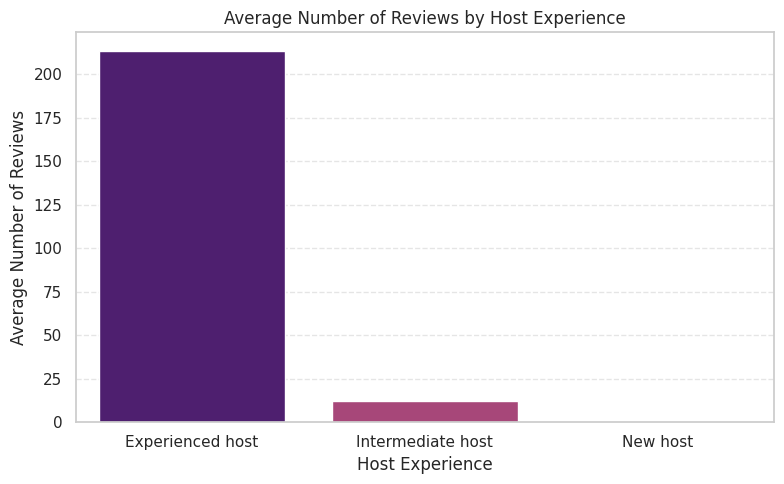

In [ ]:
#Create a filtered version
df_exp = df_cleaned.copy()

#Group by host experience and calculate average number of reviews
reviews_by_experience = df_exp.groupby('host_experience')['number_of_reviews'].mean().reset_index()

#Sort the values
reviews_by_experience = reviews_by_experience.sort_values(by='number_of_reviews', ascending=False)

#Create bar plot
plt.figure(figsize=(8, 5))
sns.barplot(data=reviews_by_experience, x='host_experience', y='number_of_reviews', palette='magma')
plt.title('Average Number of Reviews by Host Experience')
plt.xlabel('Host Experience')
plt.ylabel('Average Number of Reviews')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


<div = dir = rtl>  
  
  
כן, נראה שיש קשר ברור בין רמת הניסיון של המארח לבין מספר הביקורות שהוא מקבל
בממוצע.
מארחים מנוסים מקבלים יותר ביקורות מאשר מארחים חדשים.